# Example Monte Carlo Simulation of the 1D Ising Model

First we have to import the `IsingChain` class for the Monte Carlo simulation from `IsingChain.py` as well as additional packages that we will need.

In [1]:
from IsingChain import IsingChain
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(23) # Set random seed for reproducibility

### Generating Simulation Data

We use the `IsingChain` class to simulate the system at two different temperatures. The temperature is expressed in dimensionless units, $T^* = k_B T/J$, with $J = k_B = 1$ in the simulation. Since $J > 0$, the model describes a ferromagnetic Ising chain. For each temperature, we initialize a chain of 100 spins and run 110,000 Monte Carlo steps. The energy and magnetization are recorded after each step in the simulation history. We store each `IsingChain` object in a dictionary, using its temperature as the key, so that the simulation history can be accessed later.

In [2]:
num_spins = 100 # Number of spins in the Ising chain
num_steps = 110_000 # Number of Monte Carlo steps to simulate

temperatures = [0.3, 2.0] # Define the dimensionless temperatures to simulate
initial_chain = np.random.choice([-1, 1], size=num_spins) # Generate a random initial spin configuration

simulations_100k = {} # Create a dictionary to store the IsingChain objects for each temperature

for T in temperatures:
    ising_chain = IsingChain(num_spins=num_spins, temperature=T, initial_chain=initial_chain) # Create an IsingChain object for the current temperature

    ising_chain.simulate(num_steps) # Run the simulation for the specified number of Monte Carlo steps
    simulations_100k[T] = ising_chain # Store the IsingChain object using temperature as the key

print(f"Completed {len(simulations_100k)} simulations.")

Completed 2 simulations.


### Inspecting the Simulation Histories

Before calculating thermodynamic observables, we inspect the energy and magnetization histories at a low temperature, $T^*=0.3$, and a higher temperature, $T^*=2.0$. Both simulations start from the same randomly generated spin configuration.

At $T^*=0.3$, the energy reaches its minimum value of $E=-99$, and the magnetization approaches $M=-100$, indicating that the chain reaches a fully aligned spin configuration. In this state, flipping an interior spin costs $\Delta E=4$, with an acceptance probability of $e^{-4/T^*}\approx 1.6\times10^{-6}$. The chain can therefore remain trapped in this configuration and may not adequately sample the equilibrium distribution.

At $T^*=2.0$, the energy fluctuates around a higher mean value of approximately $-45$, while the magnetization fluctuates around zero. This behavior reflects stronger thermal fluctuations, which make spin configurations with different alignments more accessible. For an energy-increasing interior spin flip with $\Delta E=4$, the acceptance probability is $e^{-4/T^*}\approx 0.135$, substantially higher than at $T^*=0.3$. The energy and magnetization appear to settle into fluctuations around their mean values after a relatively small number of steps. 

In the following analyses, the first $10{,}000$ steps are discarded for both simulations to exclude the initial transient. This discard period is chosen based on the observed behavior of the $T^*=0.3$ simulation, which takes approximately $10{,}000$ steps to reach a fully aligned configuration.

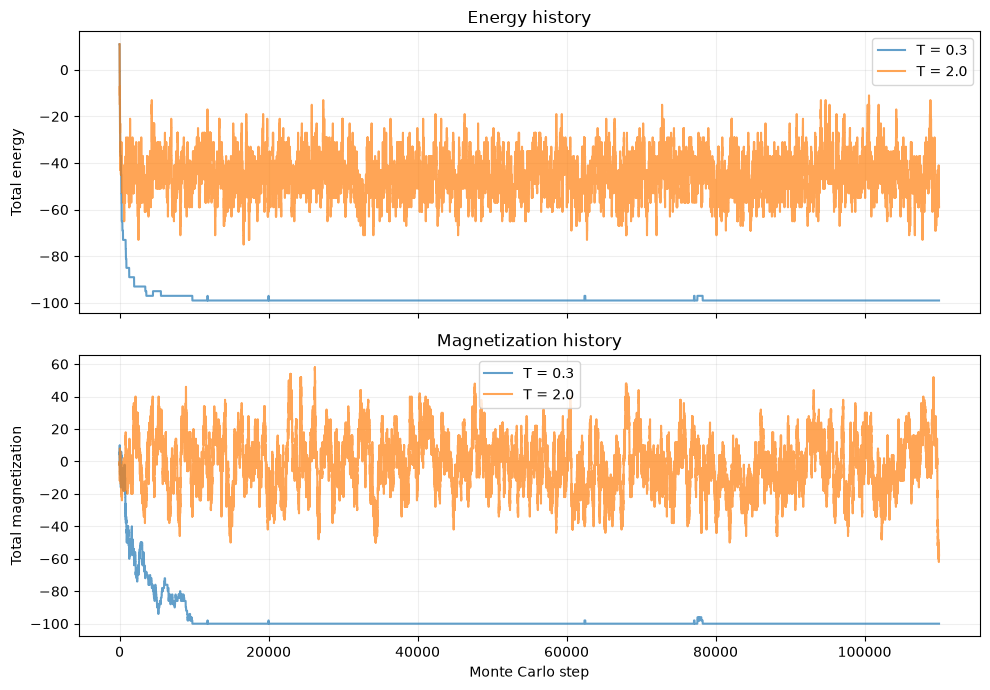

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for T in temperatures:
    energy, magnetization = simulations_100k[T].get_history() # Get the energy and magnetization histories
    steps = np.arange(len(energy)) # Generate the Monte Carlo step indices

    axes[0].plot(steps, energy, alpha=0.7,
                 label=f"T = {T:.1f}")
    axes[1].plot(steps, magnetization, alpha=0.7,
                 label=f"T = {T:.1f}")

axes[0].set_ylabel("Total energy")
axes[0].set_title("Energy history")
axes[1].set_ylabel("Total magnetization")
axes[1].set_xlabel("Monte Carlo step")
axes[1].set_title("Magnetization history")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Binning Analysis

After discarding the initial equilibration period, the remaining Monte Carlo steps are used to calculate observables such as the mean energy and magnetization. However, consecutive Monte Carlo steps are correlated, so the number of measurements alone does not indicate how accurately these mean values are estimated. Binning analysis is used to assess the statistical uncertainty of the mean by examining how it depends on the bin size.

In a binning analysis, the recorded data are divided into equal-sized bins, and the mean is calculated for each bin. The standard error of the mean is estimated from the standard deviation of the bin means:
$$
\sigma_{\langle M\rangle}=\frac{\sigma_M}{\sqrt{B}},\qquad
\sigma_{\langle E\rangle}=\frac{\sigma_E}{\sqrt{B}},
$$
where $B$ is the number of bins, and $\sigma_M$ and $\sigma_E$ are the standard deviations of the magnetization and energy bin means, respectively. The calculation is repeated for progressively larger bin sizes to investigate how the estimated standard error on the mean depends on the bin size.

This binning analysis is implemented in `analysis.py` as the method `calculate_binning_errors`. Using this method, we can plot the standard error of the mean as a function of bin size. For small bin sizes, the error is often underestimated because correlations between measurements are not fully accounted for. As the bin size increases, the estimated error typically increases until it reaches a plateau, where it becomes approximately independent of the bin size. This plateau provides an estimate of the standard error of the mean, provided that enough bins remain to estimate it reliably. Therefore, bin sizes that approach the total number of Monte Carlo steps should be avoided, as they leave too few bins for a reliable estimate.

In the plots below, it is not clear if the standard error of the mean reaches a plateau for both simulated temperatures. The history plots indicate that the $T^*=0.3$ simulation may not adequately sample the equilibrium distribution within the number of steps performed. Therefore, a longer simulation is needed to investigate whether increasing the number of Monte Carlo steps improves the sampling of the simulations.

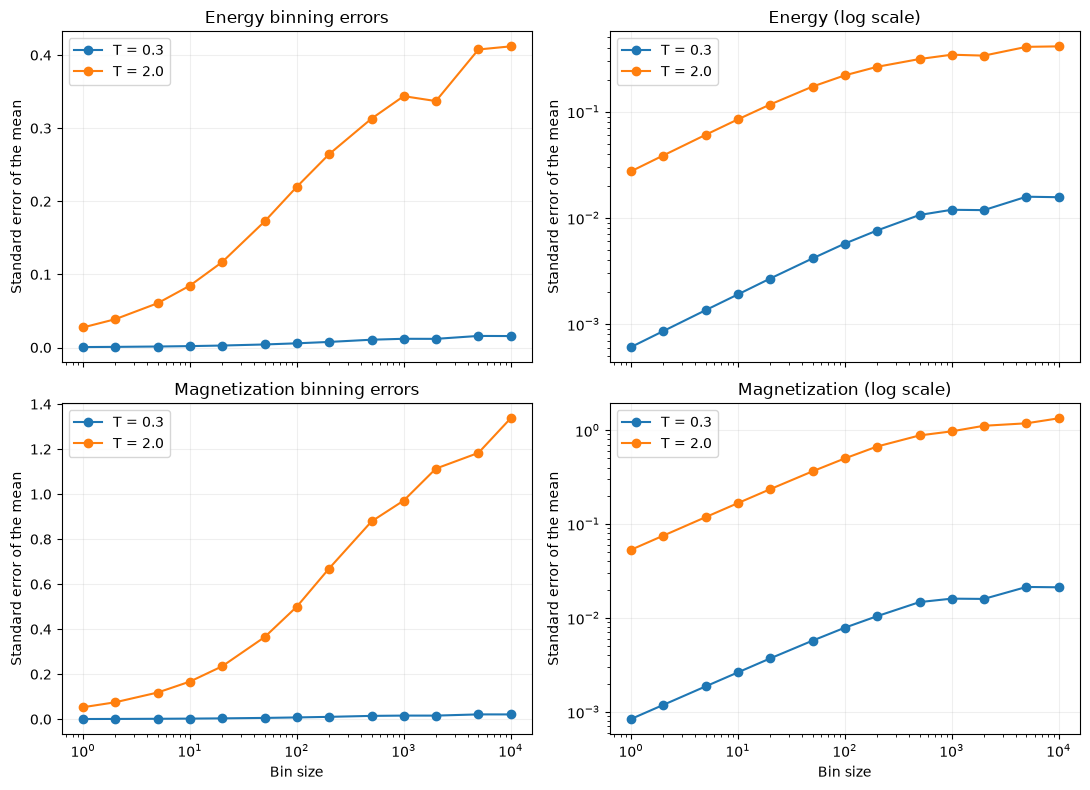

In [4]:
from analysis import calculate_binning_errors # Import the method to calculate binning errors from analysis.py

bin_sizes = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]) # Define the bin sizes to use for the binning analysis
discard = 10_000 # Number of initial Monte Carlo steps to discard for equilibration

binning_results = {}

for T, simulation in simulations_100k.items():
    energy, magnetization = simulation.get_history() 

    binning_results[T] = {
        "energy": calculate_binning_errors(energy, bin_sizes, discard=discard),
        "magnetization": calculate_binning_errors(magnetization, bin_sizes, discard=discard),
    }

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)

observables = ["energy", "magnetization"]

for row, observable in enumerate(observables):
    for T in temperatures:
        errors = binning_results[T][observable]

        axes[row, 0].plot(bin_sizes, errors, marker="o", label=f"T = {T:.1f}")

    axes[row, 0].set_title(f"{observable.capitalize()} binning errors")
    axes[row, 0].set_ylabel("Standard error of the mean")
    axes[row, 0].legend()
    axes[row, 0].grid(alpha=0.2)

    for T in temperatures:
        errors = binning_results[T][observable]

        axes[row, 1].plot(bin_sizes, errors, marker="o", label=f"T = {T:.1f}")

    axes[row, 1].set_title(f"{observable.capitalize()} (log scale)")
    axes[row, 1].set_xscale("log")
    axes[row, 1].set_yscale("log")
    axes[row, 1].set_ylabel("Standard error of the mean")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.2)

for ax in axes[-1, :]:
    ax.set_xlabel("Bin size")

plt.tight_layout()
plt.show()

To further investigate convergence, we repeat the simulations with 20 times as many Monte Carlo steps ($2{,}010{,}000$). This can take a some time (usually less than a minute).

In [5]:
num_spins = 100 # Number of spins in the Ising chain
num_steps = 2_010_000 # Number of Monte Carlo steps to simulate

temperatures = [0.3,2.0] # Define the dimensionless temperatures to simulate
initial_chain = np.random.choice([-1, 1], size=num_spins) # Generate a random initial spin configuration

simulations_2M = {} # Create a dictionary to store the IsingChain objects for each temperature

for T in temperatures:
    ising_chain = IsingChain(num_spins=num_spins, temperature=T, initial_chain=initial_chain) # Create an IsingChain object for the current temperature

    ising_chain.simulate(num_steps) # Run the simulation for the specified number of Monte Carlo steps
    simulations_2M[T] = ising_chain # Store the IsingChain object using temperature as the key

print(f"Completed {len(simulations_2M)} simulations.")

Completed 2 simulations.


The extended simulation at $T^*=0.3$ shows that the chain is not permanently trapped in a single fully aligned state: the magnetization changes from $M=-100$ to $M=+100$ throughout the simulation, while the energy remains close to its minimum value of $E=-99$. This indicates that the chain can reverse its overall magnetization while remaining close to a fully aligned configuration. Such behavior is consistent with aligned domains separated by a small number of domain walls, which can strongly affect the magnetization while contributing relatively little to the total energy.

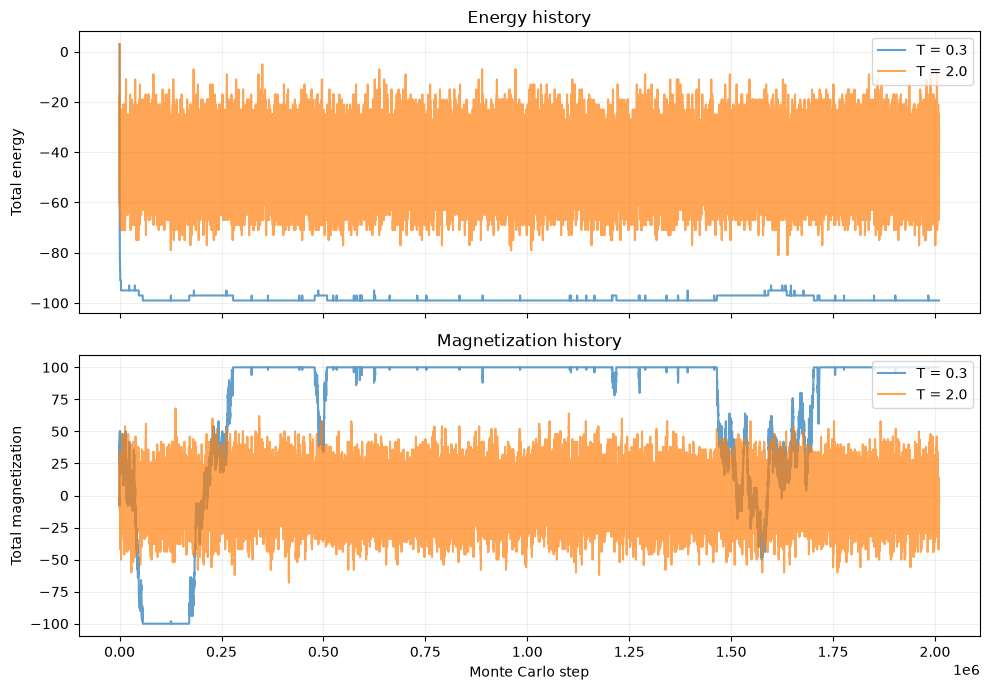

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for T in temperatures:
    energy, magnetization = simulations_2M[T].get_history() # Get the energy and magnetization histories
    steps = np.arange(len(energy)) # Generate the Monte Carlo step indices

    axes[0].plot(steps, energy, alpha=0.7,
                 label=f"T = {T:.1f}")
    axes[1].plot(steps, magnetization, alpha=0.7,
                 label=f"T = {T:.1f}")

axes[0].set_ylabel("Total energy")
axes[0].set_title("Energy history")
axes[1].set_ylabel("Total magnetization")
axes[1].set_xlabel("Monte Carlo step")
axes[1].set_title("Magnetization history")

for ax in axes:
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

The binning analysis of the extended simulations shows that the standard error of the mean reaches a plateau at $T^*=2.0$, but continues to increase over the tested bin sizes at $T^*=0.3$. This suggests that the bin sizes used are sufficient to account for correlations in the higher-temperature simulation, whereas longer timescales may still influence the low-temperature results. Therefore, the uncertainty in the estimated mean at $T^*=0.3$ remains difficult to assess reliably, and an even longer simulation may be needed.

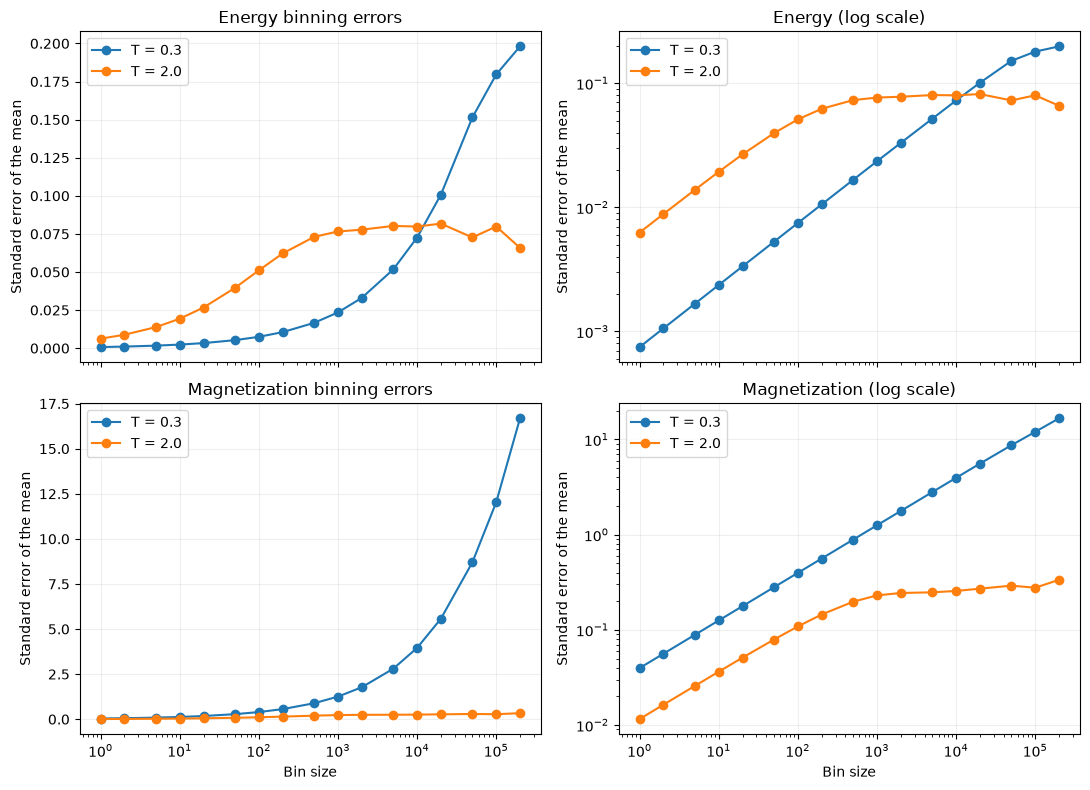

In [7]:
from analysis import calculate_binning_errors # Import the method to calculate binning errors from analysis.py

bin_sizes = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000]) # Define the bin sizes to use for the binning analysis
discard = 10_000 # Number of initial Monte Carlo steps to discard for equilibration

binning_results = {}

for T, simulation in simulations_2M.items():
    energy, magnetization = simulation.get_history() 

    binning_results[T] = {
        "energy": calculate_binning_errors(energy, bin_sizes, discard=discard),
        "magnetization": calculate_binning_errors(magnetization, bin_sizes, discard=discard),
    }

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)

observables = ["energy", "magnetization"]

for row, observable in enumerate(observables):
    for T in temperatures:
        errors = binning_results[T][observable]

        axes[row, 0].plot(bin_sizes, errors, marker="o", label=f"T = {T:.1f}")

    axes[row, 0].set_title(f"{observable.capitalize()} binning errors")
    axes[row, 0].set_ylabel("Standard error of the mean")
    axes[row, 0].legend()
    axes[row, 0].grid(alpha=0.2)

    for T in temperatures:
        errors = binning_results[T][observable]

        axes[row, 1].plot(bin_sizes, errors, marker="o", label=f"T = {T:.1f}")

    axes[row, 1].set_title(f"{observable.capitalize()} (log scale)")
    axes[row, 1].set_xscale("log")
    axes[row, 1].set_yscale("log")
    axes[row, 1].set_ylabel("Standard error of the mean")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.2)

for ax in axes[-1, :]:
    ax.set_xlabel("Bin size")

plt.tight_layout()
plt.show()

## Temperature Dependence of Thermodynamic Observables

The binning analysis examined the statistical uncertainty of the simulation results at selected temperatures. We now investigate how the thermodynamic observables depend on temperature and compare the Monte Carlo estimates with analytical predictions for the one-dimensional Ising chain with open boundary conditions.

The analytical results follow from the partition function
$$
Z_N = 2(2\cosh\beta)^{N-1}, \qquad \beta = \frac{1}{T^*},
$$
where $J=k_B=1$. The quantities considered are the mean energy per spin, heat capacity per spin, mean magnetization per spin, mean squared magnetization per spin squared, and magnetic susceptibility per spin. The analytical expressions and the Monte Carlo formulas for calculating these observables from the simulation data are derived in `Derivations.ipynb`.

The Monte Carlo estimates are calculated from the recorded simulation histories after discarding the initial $10{,}000$ steps. Since the low-temperature simulation may not adequately sample the equilibrium distribution, deviations from the analytical predictions are also useful for identifying limitations of the simulation.

First, we generate simulation data at 50 different temperatures between 0.3 and 10. Since the computation time increases with the number of Monte Carlo steps per temperature, we need to balance the simulation length against the total computational cost. Here, $200{,}000$ steps are chosen. This cell may take one minute to run.

In [8]:
num_spins = 100 # Number of spins in the Ising chain
num_steps = 200_000 # Number of Monte Carlo steps to simulate
discard = 10_000

temperatures = np.linspace(0.3, 10.0, 50) # Define the dimensionless temperatures to simulate

initial_chain = np.random.choice([-1, 1], size=num_spins) # Generate a random initial spin configuration

observables_vs_temperature = {} # Create a dictionary to store the observables for each temperature

for T in temperatures:
    simulation = IsingChain(num_spins=num_spins, temperature=T, initial_chain=initial_chain) # Create an IsingChain object for the current temperature

    simulation.simulate(num_steps) # Run the simulation for the specified number of Monte Carlo steps
    observables_vs_temperature[T] = simulation.calculate_observables(discard=discard) # Several observables can be calculated using the calculate_observables method, which returns a dictionary of observables

print(f"Completed {len(observables_vs_temperature)} simulations.")

Completed 50 simulations.


### Mean Energy and Heat Capacity

The mean energy describes the average energetic state of the chain. For the one-dimensional Ising model with open boundary conditions, its analytical value is
$$
\langle E\rangle = -(N-1)\tanh\left(\frac{1}{T^*}\right).
$$
The heat capacity measures how strongly the mean energy changes with temperature. It can be calculated from energy fluctuations:
$$
\frac{C_V}{N} = \frac{\langle E^2\rangle-\langle E\rangle^2}{N(T^*)^2}.
$$
The analytical result for the heat capacity per spin is
$$
\frac{C_V}{N} = \frac{N-1}{N(T^*)^2}\text{sech}^2\left(\frac{1}{T^*}\right).
$$

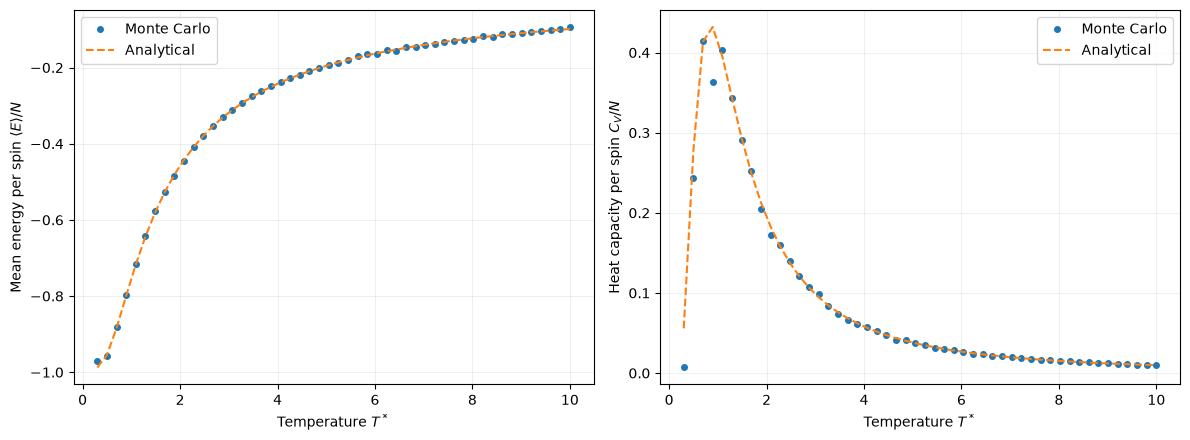

In [9]:
from analysis import analytical_mean_energy_per_spin, analytical_heat_capacity_per_spin # Import the methods to calculate the theoretical observables from analysis.py

energy_mc = np.array([observables_vs_temperature[T]["mean_energy_per_spin"] for T in temperatures]) # Get the mean energy per spin out of the dictionary

heat_capacity_mc = np.array([observables_vs_temperature[T]["heat_capacity_per_spin"] for T in temperatures]) # Get the heat capacity per spin out of the dictionary

energy_theory = analytical_mean_energy_per_spin(num_spins, temperatures) # Calculate the theoretical observables using the imported methods
heat_capacity_theory = analytical_heat_capacity_per_spin(num_spins, temperatures)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(temperatures, energy_mc, "o", markersize=4, label="Monte Carlo")
axes[0].plot(temperatures, energy_theory, "--", label="Analytical")
axes[0].set_xlabel(r"Temperature $T^*$")
axes[0].set_ylabel(r"Mean energy per spin $\langle E\rangle/N$")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(temperatures, heat_capacity_mc, "o", markersize=4, label="Monte Carlo")
axes[1].plot(temperatures, heat_capacity_theory, "--", label="Analytical")
axes[1].set_xlabel(r"Temperature $T^*$")
axes[1].set_ylabel(r"Heat capacity per spin $C_V/N$")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

The mean energy increases toward zero as the temperature rises, because thermal fluctuations reduce the alignment between neighboring spins. At low temperatures, the spins are predominantly aligned, and energy-increasing excitations are rare. As a result, the heat capacity approaches zero. At intermediate temperatures, thermal excitations become more frequent, and the energy changes more strongly with temperature, producing a maximum in the heat capacity. At higher temperatures, the heat capacity decreases again as the system approaches the high-temperature regime. For a one-dimensional Ising chain, this peak is a smooth crossover rather than a thermodynamic phase transition.

Agreement between the Monte Carlo estimates and analytical predictions indicates that the simulation reproduces the expected equilibrium averages.

### Magnetization and Susceptibility

The total magnetization is defined as
$$
M = \sum_{i=1}^{N} s_i.
$$
We compare the mean magnetization per spin, $\langle M \rangle / N$, with the mean squared magnetization per spin squared, $\langle M^2 \rangle/N^2$.

In zero external magnetic field, the analytical mean magnetization of a finite chain is zero at every nonzero temperature. This follows from the symmetry between configurations with all spins reversed. However, a Monte Carlo simulation may remain in one magnetization orientation for a long time, particularly at low temperatures, and therefore yield a nonzero estimate of $\langle M\rangle/ N$.

The mean squared magnetization provides complementary information because it does not cancel between positive and negative magnetization states. Its analytical value can be calculated using the spin correlation function
$$
\langle s_i s_j\rangle = \left[\tanh\left(\frac{1}{T^*}\right)\right]^{|i-j|}.
$$
Summing over all pairs of spins gives
$$
\langle M^2\rangle = N + 2\sum_{r=1}^{N-1}(N-r)\left[\tanh\left(\frac{1}{T^*} \right)\right]^r.
$$
Comparing these quantities helps distinguish the average magnetization from the degree of alignment within the chain.

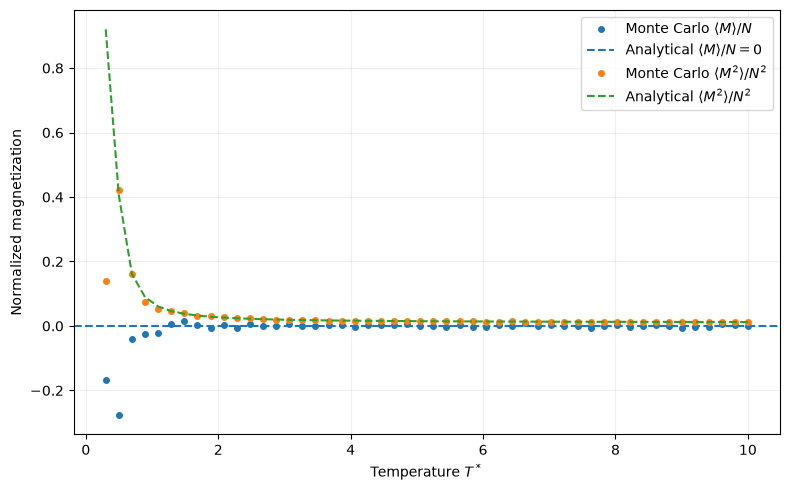

In [10]:
from analysis import analytical_mean_magnetization_squared # Import the method to calculate the theoretical magnetization squared from analysis.py

magnetization_mc = np.array([observables_vs_temperature[T]["mean_magnetization_per_spin"] for T in temperatures]) # Get the mean magnetization per spin out of the dictionary

magnetization_squared_mc = np.array([observables_vs_temperature[T]["mean_magnetization_squared_per_spin_squared"] for T in temperatures]) # Get the mean magnetization squared per spin squared out of the dictionary

magnetization_squared_theory = np.array([analytical_mean_magnetization_squared(num_spins, T) / num_spins**2 for T in temperatures]) # Calculate the theoretical mean magnetization squared using the imported methods

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(temperatures, magnetization_mc, "o", markersize=4, label=r"Monte Carlo $\langle M\rangle/N$")
ax.axhline(0, linestyle="--", label=r"Analytical $\langle M\rangle/N=0$")

ax.plot(temperatures, magnetization_squared_mc, "o", markersize=4, label=r"Monte Carlo $\langle M^2\rangle/N^2$")
ax.plot(temperatures, magnetization_squared_theory, "--", label=r"Analytical $\langle M^2\rangle/N^2$")

ax.set_xlabel(r"Temperature $T^*$")
ax.set_ylabel("Normalized magnetization")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

The analytical mean magnetization is zero because the equilibrium distribution is symmetric under reversal of all spins. At low temperatures, the Monte Carlo $\langle M \rangle$ deviates from zero, which indicates that the simulation may not have sampled both magnetization orientations sufficiently.

The mean squared magnetization remains positive even when the mean magnetization is zero. At low temperatures, neighboring spins are strongly correlated, so the chain tends to form large aligned regions and $\langle M^2 \rangle / N^2$ can approach one. As temperature increases, the correlations weaken and the normalized mean squared magnetization decreases. In the high-temperature limit, the spins become statistically independent, giving $\langle M^2 \rangle = N$ and hence $\langle M^2 \rangle/N^2 = 1/N$. For our chain of $N = 100$ spins, this limit is $0.01$.

### Magnetic Susceptibility

The magnetic susceptibility measures the response of the magnetization to an applied magnetic field. In zero field, it is related to magnetization fluctuations by
$$
\chi = \frac{\langle M^2\rangle - \langle M\rangle^2}{NT^*}.
$$
The analytical mean magnetization is zero, so the analytical susceptibility per spin is
$$
\chi_{\text{analytical}} = \frac{\langle M^2 \rangle}{N T^*}.
$$
The Monte Carlo susceptibility is calculated from the fluctuations in the sampled magnetization. Comparing it with the analytical result provides another test of whether the simulation adequately samples the equilibrium distribution.

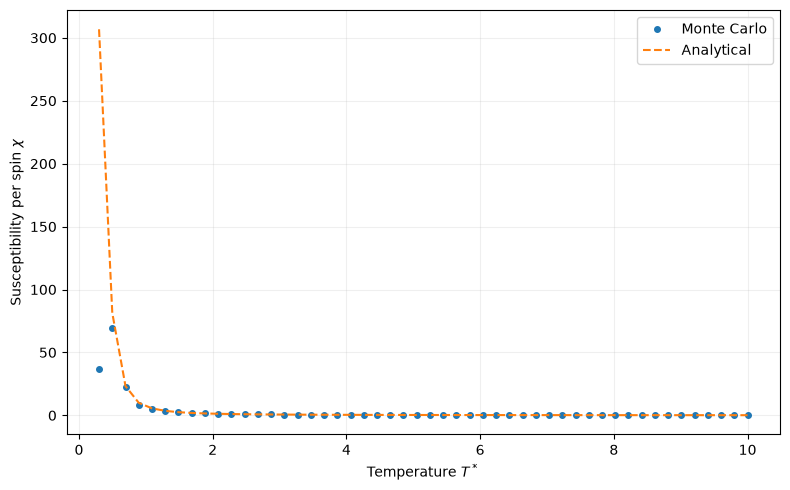

In [11]:
from analysis import analytical_susceptibility_per_spin # Import the method to calculate the theoretical susceptibility per spin from analysis.py

susceptibility_mc = np.array([observables_vs_temperature[T]["susceptibility_per_spin"]for T in temperatures]) # Get the susceptibility per spin out of the dictionary

susceptibility_theory = np.array([analytical_susceptibility_per_spin(num_spins, T) for T in temperatures]) # Calculate the theoretical susceptibility per spin using the imported method

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(temperatures, susceptibility_mc, "o", markersize=4, label="Monte Carlo")
ax.plot(temperatures, susceptibility_theory, "--", label="Analytical")

ax.set_xlabel(r"Temperature $T^*$")
ax.set_ylabel(r"Susceptibility per spin $\chi$")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

The magnetic susceptibility is proportional to the variance of the total magnetization. At low temperatures, neighboring spins are strongly correlated, so the chain tends to have a large positive or negative magnetization. Fluctuations between these configurations contribute to a large susceptibility.

Agreement between the Monte Carlo and analytical susceptibility curves supports the reliability of the estimates. However, at low temperatures, the simulation may remain trapped in one magnetization orientation and fail to sample these fluctuations sufficiently. This can lead to an underestimated susceptibility. Therefore, discrepancies at low temperatures should be interpreted with the magnetization histories and binning analysis in mind.

This example simulation is based on the Week 1 tutorial for the Computational Quantum Physics course at Radboud University Nijmegen.